In [5]:
## Lab : sklearn Model Training + Evaluation

In [6]:
pip install scikit-learn numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


### Customer Churn Prediction with KNN
### Author: Martha Olukayode
### Description: Predict whether a breast tumor is malignant or benign using KNN

In [26]:
# ============================================================
# PART 2: CUSTOMER CHURN PREDICTION USING KNN
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report
)


# ============================================================
# STEP 1: Load and Explore the Data
# ============================================================

print("Loading customer churn dataset...")

df = pd.read_csv("data/WA_Fn-UseC_-Telco-Customer-Churn.xls")

print("=== DATASET INFORMATION ===")

print("\nShape:")
print(df.shape)

print("\nColumns:")
print(df.columns)

print("\nData types:")
print(df.dtypes)

# Use the df.isnull().sum() function to get the number of null values in each of the columns should any exist
print("\nMissing values:")
print(df.isnull().sum())


Loading customer churn dataset...
=== DATASET INFORMATION ===

Shape:
(7043, 21)

Columns:
Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

Data types:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges

In [27]:
print("\nFirst five rows:")
print(df.head())

print("\nChurn distribution:")
print(df["Churn"].value_counts())


First five rows:
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies   


FEATURE DISTRIBUTIONS


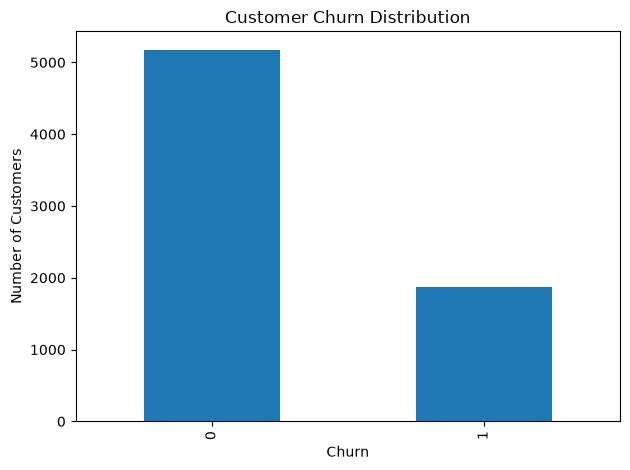

In [34]:
print("\n" + "="*50)
print("FEATURE DISTRIBUTIONS")
print("="*50)

# Visualize churn distribution
df["Churn"].value_counts().plot(
    kind="bar"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()



In [9]:
# ============================================================
# STEP 2: DATA PREPROCESSING
# ============================================================

# Customer ID does not help the model predict churn
if "customerID" in df.columns:
    df = df.drop("customerID", axis=1)


# TotalCharges is sometimes stored as text.
# Convert it to numeric.
if "TotalCharges" in df.columns:

    df["TotalCharges"] = pd.to_numeric(
        df["TotalCharges"],
        errors="coerce"
    )

# Check missing values again
print("\nMissing values after conversion:")
print(df.isnull().sum())


Missing values after conversion:
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


In [29]:
# Fill missing numeric values with the median
numeric_columns = df.select_dtypes(
    include=["number"]
).columns


for column in numeric_columns:

    df[column] = df[column].fillna(
        df[column].median()
    )


# Convert target from Yes/No to 1/0
df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Separate target BEFORE encoding
X = df.drop("Churn", axis=1)
y = df["Churn"]


# Convert categorical variables to numbers
X = pd.get_dummies(
    X,
    drop_first=True
)


print("\nData after encoding:")
print(X.head())

print("\nNumber of features after encoding:")
print(X.shape[1])


Data after encoding:
   SeniorCitizen  tenure  MonthlyCharges  customerID_0003-MKNFE  \
0              0       1           29.85                  False   
1              0      34           56.95                  False   
2              0       2           53.85                  False   
3              0      45           42.30                  False   
4              0       2           70.70                  False   

   customerID_0004-TLHLJ  customerID_0011-IGKFF  customerID_0013-EXCHZ  \
0                  False                  False                  False   
1                  False                  False                  False   
2                  False                  False                  False   
3                  False                  False                  False   
4                  False                  False                  False   

   customerID_0013-MHZWF  customerID_0013-SMEOE  customerID_0014-BMAQU  ...  \
0                  False                  False    

In [30]:
# ============================================================
# STEP 3: SPLIT THE DATA
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


print("\n=== DATA SPLIT ===")

print(
    "Training samples:",
    X_train.shape[0]
)

print(
    "Testing samples:",
    X_test.shape[0]
)


print("\nTraining Churn Distribution:")
print(y_train.value_counts(normalize=True))


print("\nTesting Churn Distribution:")
print(y_test.value_counts(normalize=True))


=== DATA SPLIT ===
Training samples: 5634
Testing samples: 1409

Training Churn Distribution:
Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64

Testing Churn Distribution:
Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64


In [32]:
# ============================================================
# STEP 4: TRAIN KNN MODEL
# ============================================================

knn = KNeighborsClassifier(
    n_neighbors=5
)

knn.fit(
    X_train,
    y_train
)


print("\nKNN model trained successfully!")


KNN model trained successfully!


In [36]:
# ============================================================
# STEP 5: Make Predictions and Evaluate
# ============================================================

y_train_pred = knn.predict(
    X_train
)

y_test_pred = knn.predict(
    X_test
)

print("\nTraining predictions:", len(y_train_pred))
print("Test predictions:", len(y_test_pred))



Training predictions: 5634
Test predictions: 1409


In [35]:

# Calculate metrics
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred)
test_recall = recall_score(y_test, y_test_pred)
test_confusion = confusion_matrix(y_test, y_test_pred)

 
print("=== Model Performance ===")
print(f"\nTraining Accuracy: {train_accuracy:.4f} ({train_accuracy*100:.2f}%)")
print(f"Test Accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"\nTest Precision: {test_precision:.4f}")
print(f"Test Recall: {test_recall:.4f}")
 
print("\n=== Confusion Matrix ===")
print(test_confusion)
#print(f"      Churn  {test_confusion[1,0]:4d}      {test_confusion[1,1]:4d}")
 
print("\n=== Classification Report ===")
print(classification_report(y_test, y_test_pred, target_names=[
            "No Churn",
            "Churn"
        ]))



=== Model Performance ===

Training Accuracy: 0.8408 (84.08%)
Test Accuracy: 0.7679 (76.79%)

Test Precision: 0.5685
Test Recall: 0.5214

=== Confusion Matrix ===
[[887 148]
 [179 195]]

=== Classification Report ===
              precision    recall  f1-score   support

    No Churn       0.83      0.86      0.84      1035
       Churn       0.57      0.52      0.54       374

    accuracy                           0.77      1409
   macro avg       0.70      0.69      0.69      1409
weighted avg       0.76      0.77      0.76      1409



In [ ]:
# ============================================================
# STEP 6: Experiment and Improve
# ============================================================
print("\n" + "="*50)
print("EXPERIMENTING WITH DIFFERENT K VALUES")
print("="*50)
 
k_values = [1, 3, 5, 7, 9, 11, 15]
results = []
 
for k in k_values:
    # Create and train model
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    
    # Make predictions
    predictions = model.predict(X_test)
    
    # Calculate accuracy
    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions)
    recall = recall_score(y_test, predictions)
    
    results.append({
        'K': k,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall
    })
    
    print(f"K={k:2d}: Accuracy={accuracy:.4f}, Precision={precision:.4f}, Recall={recall:.4f}")

# Convert results to DataFrame
results_df = pd.DataFrame(results)

print("\n=== K COMPARISON ===")
print(results_df)




EXPERIMENTING WITH DIFFERENT K VALUES
K= 1: Accuracy=0.7119, Precision=0.4570, Recall=0.4545
K= 3: Accuracy=0.7622, Precision=0.5657, Recall=0.4492
K= 5: Accuracy=0.7658, Precision=0.5791, Recall=0.4305
K= 7: Accuracy=0.7814, Precision=0.6260, Recall=0.4385
K= 9: Accuracy=0.7885, Precision=0.6532, Recall=0.4332
K=11: Accuracy=0.7864, Precision=0.6594, Recall=0.4037
K=15: Accuracy=0.7885, Precision=0.6712, Recall=0.3984

=== K COMPARISON ===
    K  Accuracy  Precision    Recall
0   1  0.711852   0.456989  0.454545
1   3  0.762243   0.565657  0.449198
2   5  0.765791   0.579137  0.430481
3   7  0.781405   0.625954  0.438503
4   9  0.788502   0.653226  0.433155
5  11  0.786373   0.659389  0.403743
6  15  0.788502   0.671171  0.398396



Best K: 9
Best Accuracy: 0.7885

Saved visualization to 'churn_knn_comparison.png'


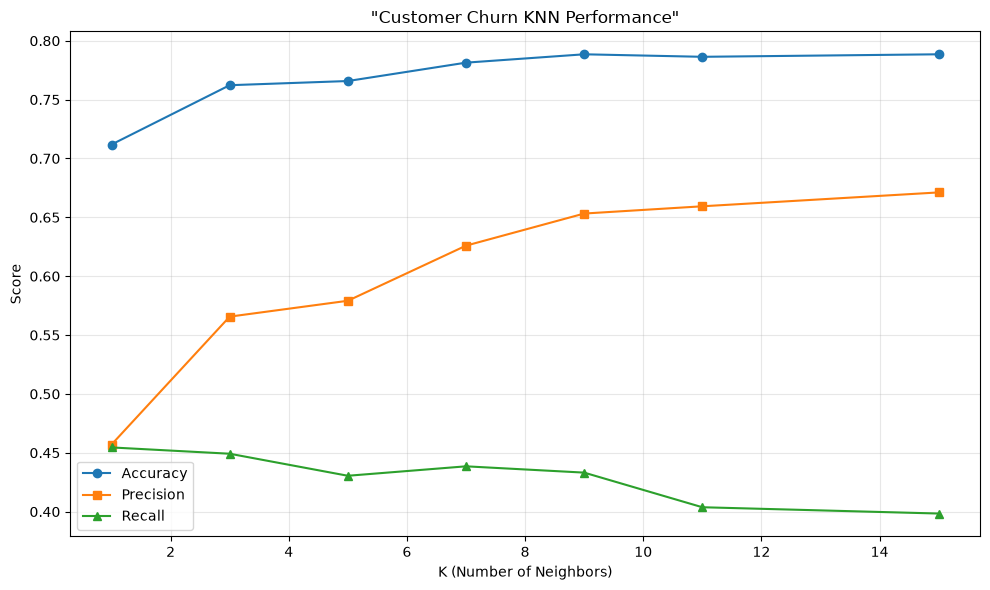

In [16]:
# Find best K based on accuracy
best_row = results_df.loc[
    results_df["Accuracy"].idxmax()
]


print("\nBest K:", int(best_row["K"]))

print(f"Best Accuracy: " f"{best_row['Accuracy']:.4f}")
 
# ============================================================
# VISUALIZE K RESULTS
# ============================================================
plt.figure(figsize=(10, 6))
plt.plot(results_df['K'], results_df['Accuracy'], marker='o', label='Accuracy')
plt.plot(results_df['K'], results_df['Precision'], marker='s', label='Precision')
plt.plot(results_df['K'], results_df['Recall'], marker='^', label='Recall')
plt.xlabel('K (Number of Neighbors)')
plt.ylabel('Score')
plt.title('"Customer Churn KNN Performance"')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('churn_knn_comparison.png', dpi=150)
print("\nSaved visualization to 'churn_knn_comparison.png'")
plt.show()

In [17]:

# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n=== FINAL MODEL SUMMARY ===")

print(
    f"Best K value: "
    f"{int(best_row['K'])}"
)

print(
    f"Best Accuracy: "
    f"{best_row['Accuracy']:.2%}"
)

print(
    f"Precision: "
    f"{best_row['Precision']:.2%}"
)

print(
    f"Recall: "
    f"{best_row['Recall']:.2%}"
)


=== FINAL MODEL SUMMARY ===
Best K value: 9
Best Accuracy: 78.85%
Precision: 65.32%
Recall: 43.32%
